In [ ]:
#Seaborn is a Python library used for data visualization. It helps us create attractive and informative statistical graphs easily.
#It is built on top of the Matplotlib library. 

#Scatterplot	Shows relationship between two variables
#Lineplot	Shows trends over time
#Barplot	Compares categories
#Histplot	Shows data distribution
#Boxplot	Identifies outliers
#Heatmap	Shows correlation using colours
#Countplot	Counts categorical values
#Pairplot	Shows relationships between multiple columns

In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns



In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("anirudhchauhan/retail-store-inventory-forecasting-dataset")

print("Path to dataset files:", path)

c:\Users\Shree\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 1.51M/1.51M [00:01<00:00, 1.24MB/s]

Extracting files...


Path to dataset files: C:\Users\Shree\.cache\kagglehub\datasets\anirudhchauhan\retail-store-inventory-forecasting-dataset\versions\1


In [3]:
df=pd.read_csv(f'{path}/retail_store_inventory.csv')

In [4]:
df.head(2)

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn


In [5]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.shape # row and column

(73100, 15)

In [6]:
df.dtypes

Date                      str
Store ID                  str
Product ID                str
Category                  str
Region                    str
Inventory Level         int64
Units Sold              int64
Units Ordered           int64
Demand Forecast       float64
Price                 float64
Discount                int64
Weather Condition         str
Holiday/Promotion       int64
Competitor Pricing    float64
Seasonality               str
dtype: object

In [10]:
df.columns

Index(['Date', 'Store ID', 'Product ID', 'Category', 'Region',
       'Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast',
       'Price', 'Discount', 'Weather Condition', 'Holiday/Promotion',
       'Competitor Pricing', 'Seasonality'],
      dtype='str')

In [12]:
df['Date']=pd.to_datetime(df['Date'])
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


In [13]:
df['Month']=df['Date'].dt.month_name()
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality,Month
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn,January
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn,January
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer,January
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn,January
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer,January


In [14]:
df['Year']=df['Date'].dt.year
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality,Month,Year
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn,January,2022
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn,January,2022
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer,January,2022
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn,January,2022
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer,January,2022


In [16]:
df.Month.unique()

<ArrowStringArray>
[  'January',  'February',     'March',     'April',       'May',      'June',
      'July',    'August', 'September',   'October',  'November',  'December']
Length: 12, dtype: str

In [18]:
df.Year.unique()

array([2022, 2023, 2024], dtype=int32)

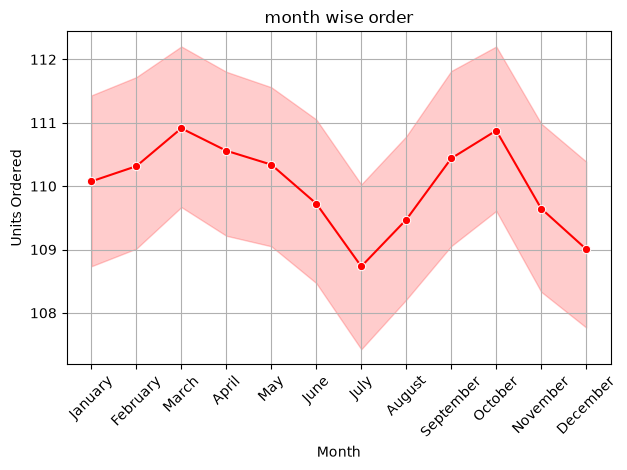

In [ ]:
#lineplot-->shows trends over time
sns.lineplot(x='Month',y='Units Ordered',data=df,marker='o',color='red',estimator='mean')
plt.title("month wise order")
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

In [23]:
df.columns

Index(['Date', 'Store ID', 'Product ID', 'Category', 'Region',
       'Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast',
       'Price', 'Discount', 'Weather Condition', 'Holiday/Promotion',
       'Competitor Pricing', 'Seasonality', 'Month', 'Year'],
      dtype='str')

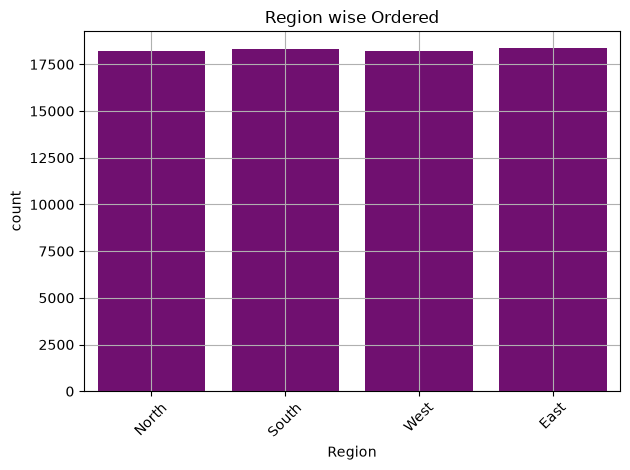

In [31]:
#Count plot
sns.countplot(x='Region',data=df,color='purple')
plt.title("Region wise Ordered")
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

In [32]:
df.columns

Index(['Date', 'Store ID', 'Product ID', 'Category', 'Region',
       'Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast',
       'Price', 'Discount', 'Weather Condition', 'Holiday/Promotion',
       'Competitor Pricing', 'Seasonality', 'Month', 'Year'],
      dtype='str')

<Axes: xlabel='Store ID', ylabel='Units Sold'>

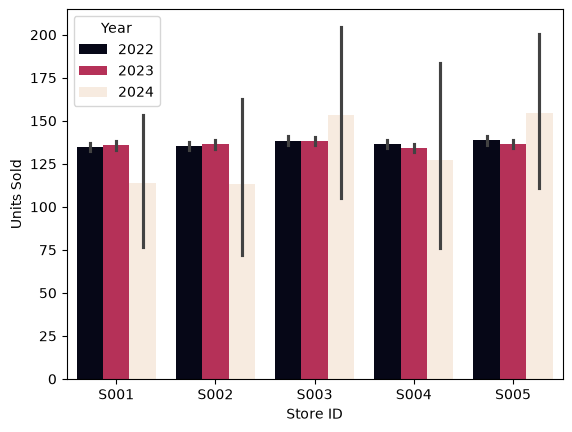

In [ ]:
sns.barplot(x='Store ID',y='Units Sold',data=df,palette='rocket',hue='Year') # mako,rocket,flare,tableau
plt.tight_layout()
plt.grid()
plt.show()

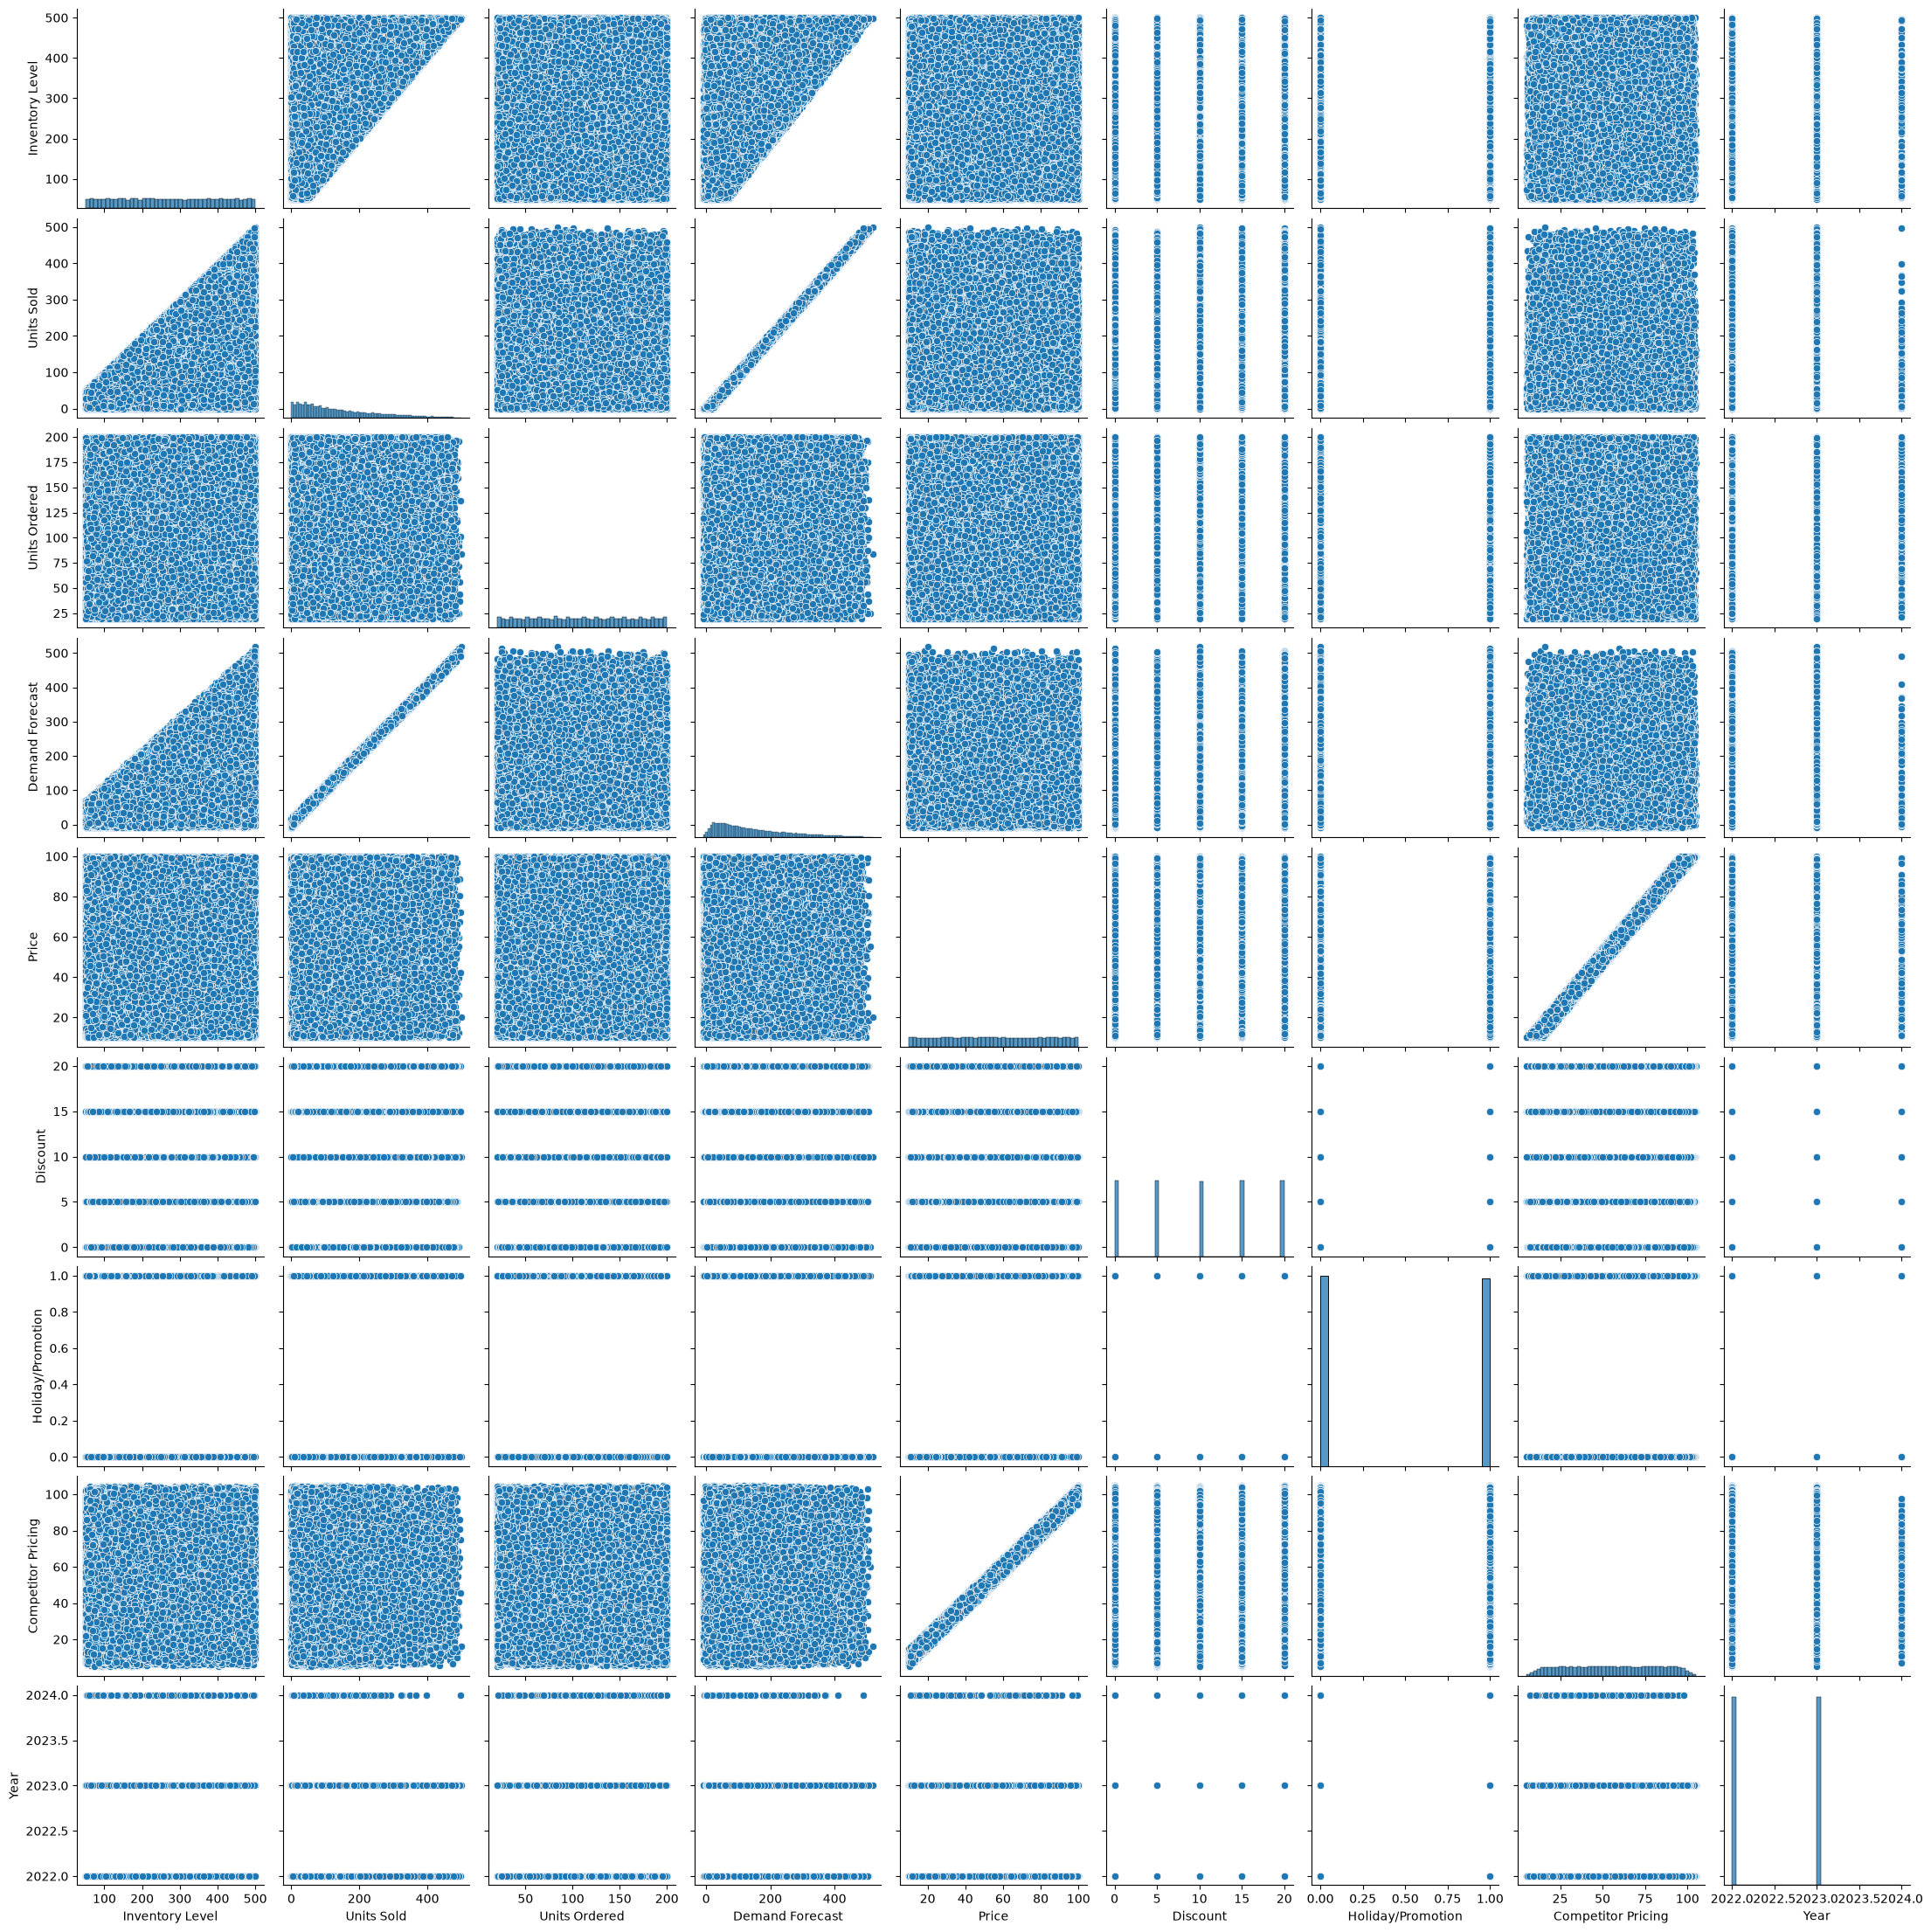

In [36]:
sns.pairplot(df)
plt.show()

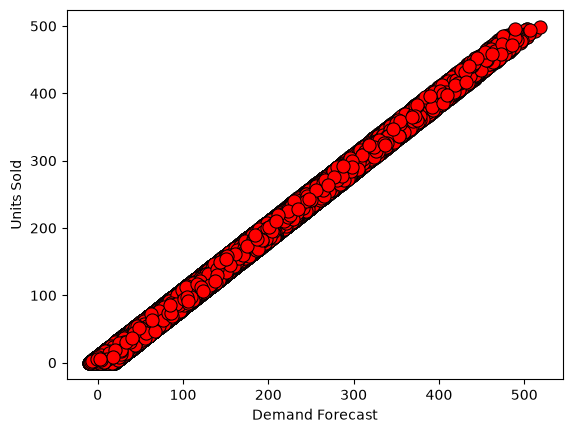

In [ ]:
sns.scatterplot(x='Demand Forecast',y='Units Sold',data=df,s=90,marker='o',color="red",edgecolor='black',alpha=1)# 0 to 1
#MARKER --> q 0,*,s,+
plt.show()

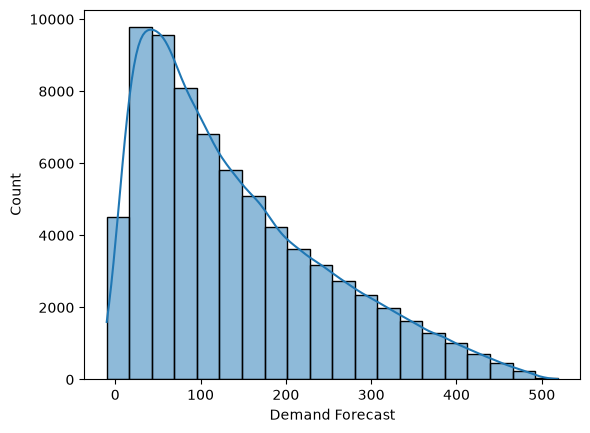

In [46]:
sns.histplot(x='Demand Forecast',data=df,kde=True,bins=20)
plt.show()

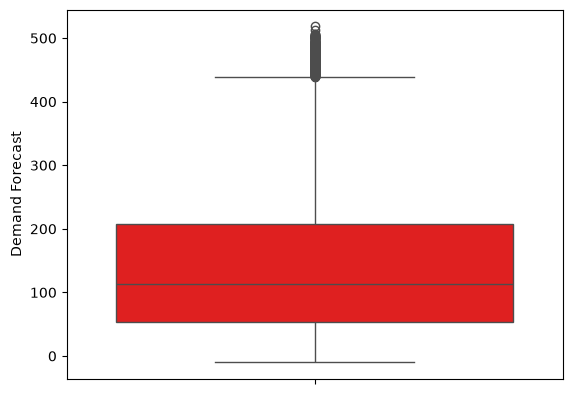

In [47]:
sns.boxplot(y='Demand Forecast',data=df,color='red')
plt.show()

In [48]:
df.corr(numeric_only=True).round=2

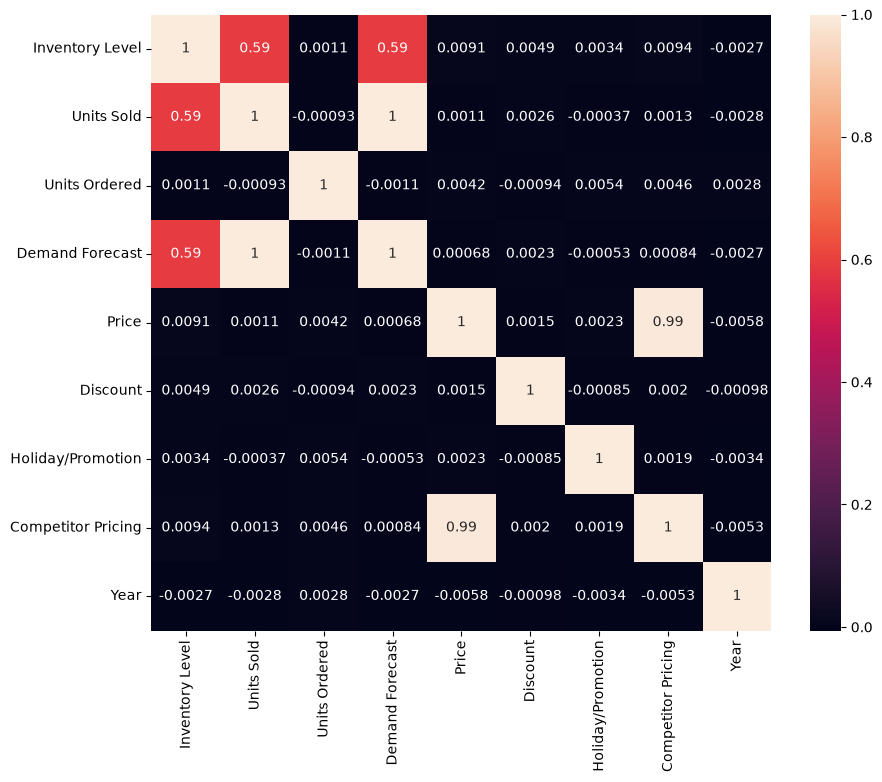

In [49]:
plt.figure(figsize=(10,8))
sns.heatmap(data=df.corr(numeric_only=True),annot=True)
plt.show()